**Live Deployment Link:** https://YOUR-APP-NAME.streamlit.app  *(replace this with your own link after deploying the Streamlit app)*

# Bike Sharing Rental Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses.

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Click it and select **`hour.csv`** from your computer. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset or disconnected. If you get a *"file not found"* error, run Step 2.1 again and re-upload `hour.csv`.

---

## Introduction

##### **Definition**
A regression ML task that predicts the **number of bikes rented in one hour** (`cnt`) from the weather and the calendar, such as temperature, humidity, wind speed, hour of the day, month and whether the day is a working day.

##### **Application**
Bike-sharing fleet planning, deciding how many bikes to place at stations at each hour, maintenance scheduling, city transport planning and demand forecasting for any rental service.

##### **Dataset**
Capital Bikeshare system, Washington D.C., USA, years 2011 and 2012. File: `hour.csv` (**17,379 hours**, 17 columns). Source: UCI Machine Learning Repository, *Bike Sharing Dataset* (Fanaee-T and Gama, 2013).

### Aim of This Notebook

> **Which of 5 regression algorithms predicts hourly bike rentals best, and how sure can we be about that answer?**

To answer it fairly we use **10-Fold Cross Validation** on the **full dataset** and compare the algorithms using **Root Mean Squared Error (RMSE)**.

The 5 algorithms are **different** from the 5 used in the Car Price Prediction notebook (Linear Regression, KNN, Decision Tree, Random Forest, Gradient Boosting).

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky. K-Fold Cross Validation removes this luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** RMSE over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10** and 17,379 rows, each test fold has about 1,738 rows and each training set has about 15,641 rows.

```
Round  1:  [TEST ] | [train] | [train] | ... | [train]
Round  2:  [train] | [TEST ] | [train] | ... | [train]
...
Round 10:  [train] | [train] | [train] | ... | [TEST ]
```

### What is RMSE?

RMSE is the square root of the average squared difference between the real and the predicted value. Here it is measured in **bikes per hour**. **Lower is better.**

### Columns of the Dataset

| Column | Meaning | Used as |
|---|---|---|
| `instant` | Record index | Dropped (ID) |
| `dteday` | Date | Dropped (month, year and weekday are already separate columns) |
| `season` | 1 winter, 2 spring, 3 summer, 4 fall | Input (categorical) |
| `yr` | 0 = 2011, 1 = 2012 | Input (numeric) |
| `mnth` | Month, 1 to 12 | Input (categorical) |
| `hr` | Hour, 0 to 23 | Input (categorical) |
| `holiday` | 1 if the day is a holiday | Input (numeric) |
| `weekday` | Day of the week, 0 = Sunday to 6 = Saturday | Input (categorical) |
| `workingday` | 1 if the day is neither a weekend nor a holiday | Input (numeric) |
| `weathersit` | 1 clear, 2 mist/cloudy, 3 light rain/snow, 4 heavy rain/snow | Input (categorical) |
| `temp` | Temperature, divided by 41 (max, °C) | Input (numeric) |
| `atemp` | Feels-like temperature, divided by 50 (max, °C) | Input (numeric) |
| `hum` | Humidity, divided by 100 (max) | Input (numeric) |
| `windspeed` | Wind speed, divided by 67 (max) | Input (numeric) |
| `casual` | Rentals by casual users | **Dropped (data leakage)** |
| `registered` | Rentals by registered users | **Dropped (data leakage)** |
| `cnt` | **Total rentals in that hour** | **Output (target)** |

# Code – Bike Sharing Rental Prediction System
## Step 1: Import Libraries

In [1]:
import json
import os
import pickle
import time

import numpy as np
import pandas as pd

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.4.4
  Pandas       : 3.0.2
  scikit-learn : 1.8.0
  Matplotlib   : 3.10.8


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select **`hour.csv`**.

If the file is already present (for example, you uploaded it earlier, or you are running the notebook on your own computer), the upload is skipped.

In [2]:
DATA_FILE = "hour.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'hour.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the hours in the dataset (the full dataset).

In [3]:
bikes = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {bikes.shape[0]:,} rows and {bikes.shape[1]} columns")

bikes.head()

Loaded dataset: 17,379 rows and 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [4]:
print("\nAttributes in Sample Data:")
print("==========================\n")
print(list(bikes.columns))

print("\nNumber of Instances in Sample Data:")
print("===================================\n")
print(len(bikes))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = bikes.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")


Attributes in Sample Data:

['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Number of Instances in Sample Data:

17379

Missing Values in Each Attribute:

No missing values


### Understanding the Output (`cnt`)

Before choosing an evaluation measure, look at the **range of the output**. The number of rentals per hour goes from a handful at night to several hundred at rush hour.

In [5]:
count_summary = bikes["cnt"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
count_summary.to_frame(name="Rentals per hour")

,Rentals per hour
count,"17,379.00"
mean,189.46
std,181.39
min,1.00
25%,40.00
50%,142.00
75%,281.00
95%,563.10
99%,782.22
max,977.00


### Why `casual` and `registered` must be dropped

`casual + registered = cnt`. If we kept them as inputs, the model could simply add them up and get a near-perfect score. That is **data leakage**: in real life we do not know them before the hour has happened. The next cell proves the relationship.

In [6]:
leak_check = (bikes["casual"] + bikes["registered"] == bikes["cnt"]).all()
print(f"casual + registered == cnt for every row: {leak_check}")

casual + registered == cnt for every row: True


## Step 3.2: Pre-process Sample Data

1. **Drop `instant`** (a record number), **`dteday`** (the date; month, year and weekday are already separate columns), and **`casual` / `registered`** (data leakage).
2. **Check for duplicates.** In the car notebook duplicates were removed because the same car could be listed twice. Here every row is a **different hour**, so a repeated combination of values is a coincidence, not a repeated record. Such rows are therefore **kept**.
3. **Missing values:** there are none. The pipeline in Step 5 still contains an imputer, which is fitted inside each cross-validation round so that nothing leaks from the test fold.

In [7]:
bikes = bikes.drop(columns=["instant", "dteday", "casual", "registered"])

identical_rows = bikes.duplicated().sum()
print(f"Columns remaining       : {list(bikes.columns)}")
print(f"Instances remaining     : {len(bikes):,}")
print(f"Rows identical in every remaining column: {identical_rows} (kept, each row is a different hour)")

Columns remaining       : ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']
Instances remaining     : 17,379
Rows identical in every remaining column: 2 (kept, each row is a different hour)


# Step 4: Feature Extraction

We separate the **input (X)** from the **output (y)**.

- **Numeric features:** `temp`, `atemp`, `hum`, `windspeed`, `yr`, `holiday`, `workingday`
- **Categorical features:** `season`, `mnth`, `hr`, `weekday`, `weathersit`

`hr`, `mnth` and `weekday` are stored as numbers, but they are **categories**, not quantities: hour 23 is not "bigger" than hour 0 in any useful way, and rentals peak at 8:00 and 17:00. One-hot encoding lets every algorithm learn a separate effect for each hour, month and weekday.

In [8]:
numeric_features = ["temp", "atemp", "hum", "windspeed", "yr", "holiday", "workingday"]
categorical_features = ["season", "mnth", "hr", "weekday", "weathersit"]
target = "cnt"

X = bikes[numeric_features + categorical_features]
y = bikes[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of hours   : {len(X):,}")

X.head()

Input features (X): 12 columns -> ['temp', 'atemp', 'hum', 'windspeed', 'yr', 'holiday', 'workingday', 'season', 'mnth', 'hr', 'weekday', 'weathersit']
Output (y)        : cnt
Number of hours   : 17,379


,temp,atemp,hum,windspeed,yr,holiday,workingday,season,mnth,hr,weekday,weathersit
0,0.24,0.29,0.81,0.00,0,0,0,1,1,0,6,1
1,0.22,0.27,0.80,0.00,0,0,0,1,1,1,6,1
2,0.22,0.27,0.80,0.00,0,0,0,1,1,2,6,1
3,0.24,0.29,0.75,0.00,0,0,0,1,1,3,6,1
4,0.24,0.29,0.75,0.00,0,0,0,1,1,4,6,1


# Step 5: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | SVR, Ridge Regression and the other algorithms behave better when features share one scale |
| Categorical | **One-hot encoding** (dense output) | Turns categories into 0/1 columns without inventing a fake order. `HistGradientBoostingRegressor` needs dense input, so `sparse_output=False` is used |

### Why put pre-processing *inside* the pipeline?

With cross validation, fitting the scaler or the imputer on the **whole** dataset first would let the training step "see" the test fold (**data leakage**). Placing them inside the pipeline makes every cross-validation round **re-fit them on the training folds only**.

`handle_unknown="ignore"` means a category that never appeared in the training folds does not crash the model.

In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

# Step 6: Define the 5 Regression Algorithms

All five are scikit-learn regressors and **none of them was used in the Car Price Prediction notebook**.

| # | Algorithm | How it predicts the number of rentals |
|---|---|---|
| 1 | **SVR** (Support Vector Regression) | Fits a curve that stays within a margin around the training points, using an RBF kernel to capture non-linear patterns |
| 2 | **Ridge Regression** | A straight-line (weighted sum) model with an L2 penalty that keeps the weights small |
| 3 | **Extra Trees** | Builds 100 trees that use random split points and averages their predictions |
| 4 | **AdaBoost** | Builds many small trees one after another, giving more weight to the hours the earlier trees predicted badly |
| 5 | **HistGradientBoosting** | A fast gradient boosting method that groups feature values into bins before building trees |

All algorithms use their **default settings** (no hyper-parameter tuning), so the comparison stays simple and fair. `random_state=42` makes the results reproducible.

**Note on SVR:** SVR is sensitive to the size of the output. Rentals reach nearly 1,000, while SVR's default margin is only 0.1. So the output is standardized during training with `TransformedTargetRegressor`, and predictions are converted back to bikes per hour automatically.

In [10]:
algorithms = {
    "SVR": TransformedTargetRegressor(regressor=SVR(), transformer=StandardScaler()),
    "Ridge Regression": Ridge(),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. SVR
  2. Ridge Regression
  3. Extra Trees
  4. AdaBoost
  5. HistGradientBoosting


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle the rows first. The file is sorted by time, so without shuffling a fold would contain only one part of the two years.
- `random_state=42`: the **same folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same hours.

In [11]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [12]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Rows": len(train_index),
        "Testing Rows": len(test_index),
        "Avg Rentals in Test Fold": y.iloc[test_index].mean(),
        "Max Rentals in Test Fold": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Rows,Testing Rows,Avg Rentals in Test Fold,Max Rentals in Test Fold
Fold (Round),,,,
1,15641,1738,183.82,901
2,15641,1738,186.20,977
3,15641,1738,185.95,899
4,15641,1738,189.78,941
5,15641,1738,190.28,943
6,15641,1738,187.55,913
7,15641,1738,193.52,968
8,15641,1738,196.39,963
9,15641,1738,195.21,976


# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds we:

1. make a **fresh copy** of the pipeline (`clone`), so nothing learned in one round is carried into the next,
2. **train** it on the training folds,
3. **predict** the rentals of the hours in the test fold,
4. calculate the **RMSE** for that fold.

### Progress Bar (tqdm)

There is one step for each algorithm on each fold, so the bar has **5 × 10 = 50 steps**. It shows the algorithm and fold being trained, the elapsed time and the estimated remaining time.

> The remaining time is an **estimate**. SVR and Extra Trees take much longer than Ridge Regression, so the estimate goes up and down. ⏱ **This step takes a few minutes.**

In [13]:
fold_rmse = {}
training_time = {}

folds = list(kfold.split(X))
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])
            predictions = fold_model.predict(X.iloc[test_index])
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<22} -> mean RMSE = {fold_rmse[name].mean():>8.2f} bikes/hour   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

  0%|          | 0/50 [00:00<?, ?fold/s]

SVR, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

SVR, fold 1/10:   2%|▏         | 1/50 [00:10<08:46, 10.74s/fold]

SVR, fold 2/10:   2%|▏         | 1/50 [00:10<08:46, 10.74s/fold]

SVR, fold 2/10:   4%|▍         | 2/50 [00:22<08:59, 11.25s/fold]

SVR, fold 3/10:   4%|▍         | 2/50 [00:22<08:59, 11.25s/fold]

SVR, fold 3/10:   6%|▌         | 3/50 [00:33<08:48, 11.24s/fold]

SVR, fold 4/10:   6%|▌         | 3/50 [00:33<08:48, 11.24s/fold]

SVR, fold 4/10:   8%|▊         | 4/50 [00:44<08:26, 11.01s/fold]

SVR, fold 5/10:   8%|▊         | 4/50 [00:44<08:26, 11.01s/fold]

SVR, fold 5/10:  10%|█         | 5/50 [00:54<08:06, 10.82s/fold]

SVR, fold 6/10:  10%|█         | 5/50 [00:54<08:06, 10.82s/fold]

SVR, fold 6/10:  12%|█▏        | 6/50 [01:05<07:53, 10.77s/fold]

SVR, fold 7/10:  12%|█▏        | 6/50 [01:05<07:53, 10.77s/fold]

SVR, fold 7/10:  14%|█▍        | 7/50 [01:16<07:46, 10.85s/fold]

SVR, fold 8/10:  14%|█▍        | 7/50 [01:16<07:46, 10.85s/fold]

SVR, fold 8/10:  16%|█▌        | 8/50 [01:27<07:33, 10.81s/fold]

SVR, fold 9/10:  16%|█▌        | 8/50 [01:27<07:33, 10.81s/fold]

SVR, fold 9/10:  18%|█▊        | 9/50 [01:37<07:19, 10.72s/fold]

SVR, fold 10/10:  18%|█▊        | 9/50 [01:37<07:19, 10.72s/fold]

SVR, fold 10/10:  20%|██        | 10/50 [01:48<07:14, 10.87s/fold]

SVR, fold 10/10:  20%|██        | 10/50 [01:48<07:14, 10.87s/fold]

Ridge Regression, fold 1/10:  20%|██        | 10/50 [01:48<07:14, 10.87s/fold]

Ridge Regression, fold 2/10:  22%|██▏       | 11/50 [01:48<07:03, 10.87s/fold]

Ridge Regression, fold 2/10:  24%|██▍       | 12/50 [01:48<03:40,  5.80s/fold]

Ridge Regression, fold 3/10:  24%|██▍       | 12/50 [01:48<03:40,  5.80s/fold]

Ridge Regression, fold 4/10:  26%|██▌       | 13/50 [01:49<03:34,  5.80s/fold]

SVR                    -> mean RMSE =    41.67 bikes/hour   (108.9 s)


Ridge Regression, fold 4/10:  28%|██▊       | 14/50 [01:49<02:05,  3.50s/fold]

Ridge Regression, fold 5/10:  28%|██▊       | 14/50 [01:49<02:05,  3.50s/fold]

Ridge Regression, fold 6/10:  30%|███       | 15/50 [01:49<02:02,  3.50s/fold]

Ridge Regression, fold 7/10:  32%|███▏      | 16/50 [01:49<01:58,  3.50s/fold]

Ridge Regression, fold 7/10:  34%|███▍      | 17/50 [01:49<01:02,  1.90s/fold]

Ridge Regression, fold 8/10:  34%|███▍      | 17/50 [01:49<01:02,  1.90s/fold]

Ridge Regression, fold 9/10:  36%|███▌      | 18/50 [01:49<01:00,  1.90s/fold]

Ridge Regression, fold 10/10:  38%|███▊      | 19/50 [01:49<00:58,  1.90s/fold]

Ridge Regression, fold 10/10:  40%|████      | 20/50 [01:49<00:34,  1.16s/fold]

Ridge Regression, fold 10/10:  40%|████      | 20/50 [01:49<00:34,  1.16s/fold]

Extra Trees, fold 1/10:  40%|████      | 20/50 [01:49<00:34,  1.16s/fold]      

Ridge Regression       -> mean RMSE =   101.91 bikes/hour   (0.5 s)


Extra Trees, fold 1/10:  40%|████      | 20/50 [02:00<00:34,  1.16s/fold]

Extra Trees, fold 1/10:  42%|████▏     | 21/50 [02:00<01:21,  2.81s/fold]

Extra Trees, fold 2/10:  42%|████▏     | 21/50 [02:00<01:21,  2.81s/fold]

Extra Trees, fold 2/10:  44%|████▍     | 22/50 [02:12<02:02,  4.39s/fold]

Extra Trees, fold 3/10:  44%|████▍     | 22/50 [02:12<02:02,  4.39s/fold]

Extra Trees, fold 3/10:  46%|████▌     | 23/50 [02:23<02:39,  5.92s/fold]

Extra Trees, fold 4/10:  46%|████▌     | 23/50 [02:23<02:39,  5.92s/fold]

Extra Trees, fold 4/10:  48%|████▊     | 24/50 [02:35<03:08,  7.26s/fold]

Extra Trees, fold 5/10:  48%|████▊     | 24/50 [02:35<03:08,  7.26s/fold]

Extra Trees, fold 5/10:  50%|█████     | 25/50 [02:47<03:28,  8.33s/fold]

Extra Trees, fold 6/10:  50%|█████     | 25/50 [02:47<03:28,  8.33s/fold]

Extra Trees, fold 6/10:  52%|█████▏    | 26/50 [02:58<03:40,  9.17s/fold]

Extra Trees, fold 7/10:  52%|█████▏    | 26/50 [02:58<03:40,  9.17s/fold]

Extra Trees, fold 7/10:  54%|█████▍    | 27/50 [03:10<03:45,  9.81s/fold]

Extra Trees, fold 8/10:  54%|█████▍    | 27/50 [03:10<03:45,  9.81s/fold]

Extra Trees, fold 8/10:  56%|█████▌    | 28/50 [03:21<03:45, 10.25s/fold]

Extra Trees, fold 9/10:  56%|█████▌    | 28/50 [03:21<03:45, 10.25s/fold]

Extra Trees, fold 9/10:  58%|█████▊    | 29/50 [03:33<03:42, 10.60s/fold]

Extra Trees, fold 10/10:  58%|█████▊    | 29/50 [03:33<03:42, 10.60s/fold]

Extra Trees, fold 10/10:  60%|██████    | 30/50 [03:45<03:42, 11.13s/fold]

Extra Trees, fold 10/10:  60%|██████    | 30/50 [03:45<03:42, 11.13s/fold]

AdaBoost, fold 1/10:  60%|██████    | 30/50 [03:45<03:42, 11.13s/fold]    

Extra Trees            -> mean RMSE =    45.51 bikes/hour   (116.2 s)


AdaBoost, fold 1/10:  62%|██████▏   | 31/50 [03:46<02:35,  8.17s/fold]

AdaBoost, fold 2/10:  62%|██████▏   | 31/50 [03:46<02:35,  8.17s/fold]

AdaBoost, fold 3/10:  64%|██████▍   | 32/50 [03:47<02:26,  8.17s/fold]

AdaBoost, fold 3/10:  66%|██████▌   | 33/50 [03:48<01:23,  4.91s/fold]

AdaBoost, fold 4/10:  66%|██████▌   | 33/50 [03:48<01:23,  4.91s/fold]

AdaBoost, fold 4/10:  68%|██████▊   | 34/50 [03:49<01:03,  3.96s/fold]

AdaBoost, fold 5/10:  68%|██████▊   | 34/50 [03:49<01:03,  3.96s/fold]

AdaBoost, fold 5/10:  70%|███████   | 35/50 [03:50<00:48,  3.26s/fold]

AdaBoost, fold 6/10:  70%|███████   | 35/50 [03:50<00:48,  3.26s/fold]

AdaBoost, fold 6/10:  72%|███████▏  | 36/50 [03:52<00:38,  2.74s/fold]

AdaBoost, fold 7/10:  72%|███████▏  | 36/50 [03:52<00:38,  2.74s/fold]

AdaBoost, fold 7/10:  74%|███████▍  | 37/50 [03:53<00:29,  2.23s/fold]

AdaBoost, fold 8/10:  74%|███████▍  | 37/50 [03:53<00:29,  2.23s/fold]

AdaBoost, fold 8/10:  76%|███████▌  | 38/50 [03:54<00:22,  1.84s/fold]

AdaBoost, fold 9/10:  76%|███████▌  | 38/50 [03:54<00:22,  1.84s/fold]

AdaBoost, fold 9/10:  78%|███████▊  | 39/50 [03:54<00:16,  1.53s/fold]

AdaBoost, fold 10/10:  78%|███████▊  | 39/50 [03:54<00:16,  1.53s/fold]

AdaBoost, fold 10/10:  80%|████████  | 40/50 [03:55<00:13,  1.32s/fold]

AdaBoost, fold 10/10:  80%|████████  | 40/50 [03:55<00:13,  1.32s/fold]

HistGradientBoosting, fold 1/10:  80%|████████  | 40/50 [03:55<00:13,  1.32s/fold]

AdaBoost               -> mean RMSE =   141.42 bikes/hour   (10.0 s)


HistGradientBoosting, fold 1/10:  82%|████████▏ | 41/50 [03:56<00:10,  1.16s/fold]

HistGradientBoosting, fold 2/10:  82%|████████▏ | 41/50 [03:56<00:10,  1.16s/fold]

HistGradientBoosting, fold 2/10:  84%|████████▍ | 42/50 [03:57<00:08,  1.05s/fold]

HistGradientBoosting, fold 3/10:  84%|████████▍ | 42/50 [03:57<00:08,  1.05s/fold]

HistGradientBoosting, fold 3/10:  86%|████████▌ | 43/50 [03:58<00:07,  1.01s/fold]

HistGradientBoosting, fold 4/10:  86%|████████▌ | 43/50 [03:58<00:07,  1.01s/fold]

HistGradientBoosting, fold 4/10:  88%|████████▊ | 44/50 [03:59<00:05,  1.01fold/s]

HistGradientBoosting, fold 5/10:  88%|████████▊ | 44/50 [03:59<00:05,  1.01fold/s]

HistGradientBoosting, fold 5/10:  90%|█████████ | 45/50 [03:59<00:04,  1.03fold/s]

HistGradientBoosting, fold 6/10:  90%|█████████ | 45/50 [03:59<00:04,  1.03fold/s]

HistGradientBoosting, fold 6/10:  92%|█████████▏| 46/50 [04:00<00:03,  1.09fold/s]

HistGradientBoosting, fold 7/10:  92%|█████████▏| 46/50 [04:00<00:03,  1.09fold/s]

HistGradientBoosting, fold 7/10:  94%|█████████▍| 47/50 [04:01<00:02,  1.11fold/s]

HistGradientBoosting, fold 8/10:  94%|█████████▍| 47/50 [04:01<00:02,  1.11fold/s]

HistGradientBoosting, fold 8/10:  96%|█████████▌| 48/50 [04:02<00:01,  1.09fold/s]

HistGradientBoosting, fold 9/10:  96%|█████████▌| 48/50 [04:02<00:01,  1.09fold/s]

HistGradientBoosting, fold 9/10:  98%|█████████▊| 49/50 [04:03<00:00,  1.12fold/s]

HistGradientBoosting, fold 10/10:  98%|█████████▊| 49/50 [04:03<00:00,  1.12fold/s]

HistGradientBoosting, fold 10/10: 100%|██████████| 50/50 [04:04<00:00,  1.14fold/s]

HistGradientBoosting, fold 10/10: 100%|██████████| 50/50 [04:04<00:00,  1.14fold/s]

Done: 100%|██████████| 50/50 [04:04<00:00,  1.14fold/s]                            

Done: 100%|██████████| 50/50 [04:04<00:00,  4.89s/fold]

HistGradientBoosting   -> mean RMSE =    46.80 bikes/hour   (8.6 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation and each column is one algorithm. The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

In [14]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("{:,.2f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,SVR,Ridge Regression,Extra Trees,AdaBoost,HistGradientBoosting
Fold,,,,,
Fold 1,39.38,100.02,43.92,140.63,44.41
Fold 2,43.73,100.73,45.55,148.48,46.21
Fold 3,36.68,100.20,41.65,140.77,43.05
Fold 4,44.39,102.20,49.89,142.59,48.76
Fold 5,43.62,104.51,47.50,144.09,48.60
Fold 6,43.91,99.12,46.68,140.78,48.89
Fold 7,38.41,100.46,44.06,138.30,44.00
Fold 8,41.05,103.27,43.91,141.24,47.60
Fold 9,42.97,103.34,45.10,139.42,48.37


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds. This is the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds. A small value means the algorithm is consistent |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Rentals** | Mean RMSE divided by the average number of rentals per hour |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [15]:
average_count = y.mean()

summary = pd.DataFrame({
    "Mean RMSE": per_fold_table.mean(),
    "Std RMSE": per_fold_table.std(),
    "Best Fold RMSE": per_fold_table.min(),
    "Worst Fold RMSE": per_fold_table.max(),
    "RMSE as % of Avg Rentals": per_fold_table.mean() / average_count * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average number of rentals per hour in this data: {average_count:,.2f}\n")

(summary.style
    .format({
        "Mean RMSE": "{:,.2f}",
        "Std RMSE": "{:,.2f}",
        "Best Fold RMSE": "{:,.2f}",
        "Worst Fold RMSE": "{:,.2f}",
        "RMSE as % of Avg Rentals": "{:.1f}%",
        "Time (s)": "{:.2f}",
    })
    .highlight_min(subset=["Mean RMSE"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average number of rentals per hour in this data: 189.46



,Rank,Mean RMSE,Std RMSE,Best Fold RMSE,Worst Fold RMSE,RMSE as % of Avg Rentals,Time (s)
Algorithm,,,,,,,
SVR,1,41.67,2.67,36.68,44.39,22.0%,108.86
Extra Trees,2,45.51,2.32,41.65,49.89,24.0%,116.23
HistGradientBoosting,3,46.80,2.22,43.05,48.89,24.7%,8.64
Ridge Regression,4,101.91,2.10,99.12,105.27,53.8%,0.49
AdaBoost,5,141.42,3.09,137.92,148.48,74.6%,10.02


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better). The black whisker shows ± 1 standard deviation across the 10 folds.

**Chart 2** shows the RMSE of **every individual fold** as a dot, so you can see how spread out each algorithm's results are.

The chart is also saved as `bike_rmse_comparison.png`.

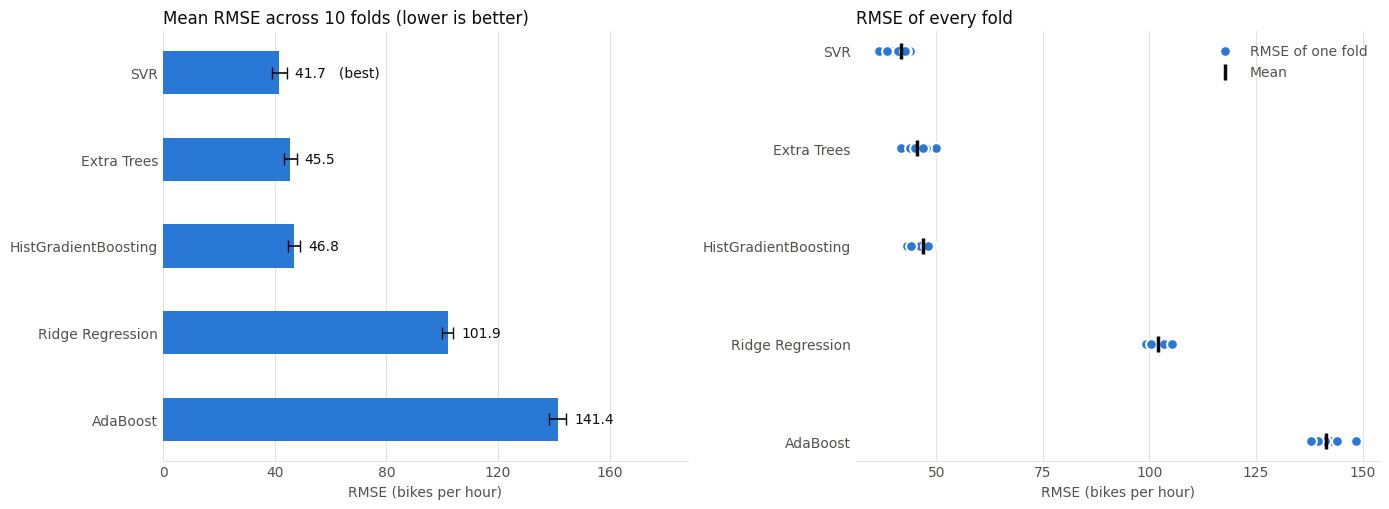

In [16]:
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

means = summary["Mean RMSE"]
stds = summary["Std RMSE"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"{means[name]:,.1f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (bikes per hour)", color=MUTED_TEXT)

for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(per_fold_table[name].mean(), i, s=140, marker="|", color=TEXT_COLOR,
                linewidth=2.5, zorder=4, label="Mean" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
style_axis(ax2)
ax2.set_title("RMSE of every fold", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (bikes per hour)", color=MUTED_TEXT)
ax2.legend(loc="upper right", frameon=False, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.savefig("bike_rmse_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9.4: Observations

The observations below are **generated from the results of your own run**, so they always match the tables above.

In [17]:
best_name = summary.index[0]
second_name = summary.index[1]
worst_name = summary.index[-1]

best_mean = summary.loc[best_name, "Mean RMSE"]
best_std = summary.loc[best_name, "Std RMSE"]
second_mean = summary.loc[second_name, "Mean RMSE"]
worst_mean = summary.loc[worst_name, "Mean RMSE"]
gap = second_mean - best_mean

fastest_name = summary["Time (s)"].idxmin()
slowest_name = summary["Time (s)"].idxmax()

wins = per_fold_table.idxmin(axis=1).value_counts()

print(f"1. {best_name} has the lowest mean RMSE ({best_mean:,.2f} bikes/hour, +/- {best_std:,.2f}), "
      f"which is {summary.loc[best_name, 'RMSE as % of Avg Rentals']:.1f}% of the average hourly rentals ({average_count:,.1f}).")

if gap < best_std:
    print(f"2. {second_name} is second ({second_mean:,.2f}). The gap ({gap:,.2f}) is smaller than the "
          f"standard deviation of {best_name} ({best_std:,.2f}), so the two are practically tied.")
else:
    print(f"2. {second_name} is second ({second_mean:,.2f}). The gap ({gap:,.2f}) is larger than the "
          f"standard deviation of {best_name} ({best_std:,.2f}), so {best_name} is clearly better.")

print(f"3. {worst_name} is the weakest ({worst_mean:,.2f}), about {worst_mean / best_mean:.1f}x the error of {best_name}.")

print(f"4. {best_name} won {int(wins.get(best_name, 0))} of {K} folds. "
      f"Fold-wise winners: " + ", ".join(f"{n} ({c})" for n, c in wins.items()) + ".")

print(f"5. Speed: {fastest_name} is the fastest ({summary.loc[fastest_name, 'Time (s)']:.1f} s for all folds) and "
      f"{slowest_name} is the slowest ({summary.loc[slowest_name, 'Time (s)']:.1f} s).")

print(f"6. {K} folds test every algorithm {K} times on about {len(X) // K:,} hours each, "
      f"so the ranking is far more reliable than a single train/test split.")

1. SVR has the lowest mean RMSE (41.67 bikes/hour, +/- 2.67), which is 22.0% of the average hourly rentals (189.5).
2. Extra Trees is second (45.51). The gap (3.84) is larger than the standard deviation of SVR (2.67), so SVR is clearly better.
3. AdaBoost is the weakest (141.42), about 3.4x the error of SVR.
4. SVR won 10 of 10 folds. Fold-wise winners: SVR (10).
5. Speed: Ridge Regression is the fastest (0.5 s for all folds) and Extra Trees is the slowest (116.2 s).
6. 10 folds test every algorithm 10 times on about 1,737 hours each, so the ranking is far more reliable than a single train/test split.


# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used to measure performance and are now thrown away.

We select the algorithm with the **lowest mean RMSE** from the summary table.

In [18]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : {best_mean_rmse:,.2f} bikes/hour (+/- {best_std_rmse:,.2f})")

Best algorithm : SVR
Expected RMSE  : 41.67 bikes/hour (+/- 2.67)


## Step 10.2: Train the Best Algorithm on All the Data

Now that we know which algorithm works best, we train it on **all 17,379 hours**. There is no separate test set here, because the cross-validation RMSE from Step 9 is already our estimate of how well the model will perform on new, unseen hours.

In [19]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} hours.")

Final SVR model trained on 17,379 hours.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it predicts directly from raw feature values.

Two files are written:

- `bike_rental_model.pkl`: the trained model, which you submit and which the Streamlit app loads.
- `model_info.json`: the name of the best algorithm, its cross-validation RMSE and the scikit-learn version. The Streamlit app uses it to show the typical error and to rebuild the model automatically if the scikit-learn version differs.

To download both files in Colab, set `DOWNLOAD_MODEL = True` and run the cell again, or use the **Files** panel (folder icon) on the left.

In [20]:
MODEL_FILE = "bike_rental_model.pkl"
INFO_FILE = "model_info.json"
DOWNLOAD_MODEL = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

model_info = {
    "best_algorithm": best_algorithm_name,
    "cv_mean_rmse": float(best_mean_rmse),
    "cv_std_rmse": float(best_std_rmse),
    "average_rentals_per_hour": float(average_count),
    "folds": K,
    "rows": int(len(X)),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "all_algorithms_mean_rmse": {name: float(value) for name, value in summary["Mean RMSE"].items()},
    "sklearn_version": sklearn.__version__,
}

with open(INFO_FILE, "w", encoding="utf-8") as f:
    json.dump(model_info, f, indent=2)

print(f"Trained model saved as '{MODEL_FILE}'")
print(f"Model information saved as '{INFO_FILE}'")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)
    files.download(INFO_FILE)

Trained model saved as 'bike_rental_model.pkl'
Model information saved as 'model_info.json'


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example hour below, so that **Run all** works without stopping. To type in your own values, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

The inputs use **real units** (°C, %, km/h). Step 11.2 converts them to the normalized form used in the dataset.

In [21]:
USE_INTERACTIVE_INPUT = False

example_hour = {
    "yr": 1,
    "season": 3,
    "mnth": 7,
    "hr": 17,
    "weekday": 3,
    "holiday": 0,
    "weathersit": 1,
    "temp_c": 28.0,
    "feels_like_c": 30.0,
    "humidity_percent": 55.0,
    "wind_kmh": 12.0,
}

def get_hour_input():
    print("Enter the conditions of the hour (allowed values are shown):")
    return {
        "yr": int(input("Year (0 = 2011, 1 = 2012): ")),
        "season": int(input("Season (1 winter, 2 spring, 3 summer, 4 fall): ")),
        "mnth": int(input("Month (1-12): ")),
        "hr": int(input("Hour (0-23): ")),
        "weekday": int(input("Weekday (0 = Sunday ... 6 = Saturday): ")),
        "holiday": int(input("Holiday (0 = no, 1 = yes): ")),
        "weathersit": int(input("Weather (1 clear, 2 mist/cloudy, 3 light rain/snow, 4 heavy rain/snow): ")),
        "temp_c": float(input("Temperature in C (0-41): ")),
        "feels_like_c": float(input("Feels-like temperature in C (0-50): ")),
        "humidity_percent": float(input("Humidity in % (0-100): ")),
        "wind_kmh": float(input("Wind speed in km/h (0-67): ")),
    }

user_input = get_hour_input() if USE_INTERACTIVE_INPUT else example_hour

print("Conditions of the hour:")
for feature, value in user_input.items():
    print(f"  {feature:<18}: {value}")

Conditions of the hour:
  yr                : 1
  season            : 3
  mnth              : 7
  hr                : 17
  weekday           : 3
  holiday           : 0
  weathersit        : 1
  temp_c            : 28.0
  feels_like_c      : 30.0
  humidity_percent  : 55.0
  wind_kmh          : 12.0


## Step 11.2: Convert User Input into Feature Vector

The dataset stores the weather in normalized form (`temp` = °C / 41, `atemp` = °C / 50, `hum` = % / 100, `windspeed` = km/h / 67), and `workingday` is 1 only on weekdays that are not holidays. The feature vector must have **exactly the same columns, in the same order,** as the training data. The saved pipeline scales and one-hot encodes it automatically.

In [22]:
is_working_day = int(user_input["weekday"] in (1, 2, 3, 4, 5) and user_input["holiday"] == 0)

feature_vector = pd.DataFrame([{
    "temp": user_input["temp_c"] / 41,
    "atemp": user_input["feels_like_c"] / 50,
    "hum": user_input["humidity_percent"] / 100,
    "windspeed": user_input["wind_kmh"] / 67,
    "yr": user_input["yr"],
    "holiday": user_input["holiday"],
    "workingday": is_working_day,
    "season": user_input["season"],
    "mnth": user_input["mnth"],
    "hr": user_input["hr"],
    "weekday": user_input["weekday"],
    "weathersit": user_input["weathersit"],
}])[numeric_features + categorical_features]

feature_vector

,temp,atemp,hum,windspeed,yr,holiday,workingday,season,mnth,hr,weekday,weathersit
0,0.68,0.60,0.55,0.18,1,0,1,3,7,17,3,1


## Step 11.3: Load the Saved Model

In [23]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'bike_rental_model.pkl': TransformedTargetRegressor


## Step 11.4: Model Prediction

Apply the model to the feature vector of the unseen hour and return the prediction to the user. A count cannot be negative, so the prediction is limited to 0 or more and rounded to whole bikes.

In [24]:
predicted_rentals = max(0, round(float(loaded_model.predict(feature_vector)[0])))

print(f"Predicted bike rentals in this hour: {predicted_rentals}")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about {best_mean_rmse:,.0f} bikes/hour")

Predicted bike rentals in this hour: 854
Typical error (cross-validation RMSE of SVR): about 42 bikes/hour


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (for example, the bike-sharing operator) is used to improve the model. Potential improvements for this system:

1. **Add more features:** public events, holidays near weekends, precipitation amounts and rolling features such as the rentals in the previous hours.
2. **Tune hyper-parameters:** for example SVR's `C` and `epsilon`, the number of trees in Extra Trees, or the learning rate in HistGradientBoosting. Use cross validation (`GridSearchCV`) to choose them.
3. **Predict casual and registered users separately:** the two groups behave differently (commuters versus leisure riders).
4. **Collect more recent data:** the dataset covers only 2011 and 2012.

# Step 13: Model Deployment (Streamlit Web App)

The project folder contains `app.py`, `bike_model.py`, `hour.csv`, `bike_rental_model.pkl`, `model_info.json` and `requirements.txt`.

1. Create a **public GitHub repository** and upload all files of the folder.
2. Go to **https://share.streamlit.io** and sign in with GitHub.
3. Click **Create app**, choose the repository and the branch, and set the **main file path** to `app.py`.
4. Choose **Python 3.12** under *Advanced settings* and click **Deploy**.
5. Copy the live link and paste it into the **first line of this notebook**.

To test it on your own computer first: `pip install -r requirements.txt`, then `streamlit run app.py`.

In [25]:
print(f"Cross-validation compared {len(algorithms)} algorithms with {K}-fold cross validation on {len(X):,} hours.")
print(f"Best algorithm: {best_algorithm_name} with mean RMSE {best_mean_rmse:,.2f} bikes/hour.")
print(f"Deployed model file: {MODEL_FILE}")

Cross-validation compared 5 algorithms with 10-fold cross validation on 17,379 hours.
Best algorithm: SVR with mean RMSE 41.67 bikes/hour.
Deployed model file: bike_rental_model.pkl


# Conclusion

In this notebook we compared **5 regression algorithms** (SVR, Ridge Regression, Extra Trees, AdaBoost and HistGradientBoosting) on the **full Bike Sharing dataset (17,379 hours)** using **10-fold cross validation** and **RMSE**.

- The best algorithm by mean RMSE (shown in Step 9.2) was trained on all the data, saved, and used to predict the rentals of a new hour.
- Hour of the day is by far the strongest driver of demand (rentals peak around 8:00 and 17:00), followed by the working-day flag, the year and the temperature. Algorithms that can model **non-linear** patterns clearly beat the straight-line model: Ridge Regression has more than twice the error of SVR, Extra Trees and HistGradientBoosting.
- RMSE is measured in **bikes per hour**, so it can be read directly: it is the typical size of the prediction error.
- Cross validation makes the comparison **reliable**, because every algorithm is tested 10 times on the same folds.

*Data source: Fanaee-T, Hadi, and Gama, Joao, "Event labeling combining ensemble detectors and background knowledge", Progress in Artificial Intelligence (2013), pp. 1-15, Springer. Hosted by the UCI Machine Learning Repository.*